# Лабораторная работа 5
## Стохастический градиентный спуск, импульс Нестерова, Adam и регуляризация

### 1. Данные

В Lab5 задана отдельная выборка из 12 пар $(x_i,y_i)$; все производные **при обучении** вычисляются центральными разностями. Аналитическое решение для полиномов
нужно только как независимая проверка.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

LAB_DIR = Path.cwd().resolve()
if not (LAB_DIR / 'optimization.py').is_file():
    LAB_DIR = LAB_DIR / 'Lab5'
if not (LAB_DIR / 'optimization.py').is_file():
    raise FileNotFoundError('Рабочим каталогом должен быть корень проекта или Lab5')
sys.path.insert(0, str(LAB_DIR))
from optimization import (PARAMETERS, WEIGHT_MASK, target_function, golden_section,
                          numerical_gradient, objective, predict, initialize, train,
                          predict_saved)
from experiments import (MODELS, METHODS, BATCH_SIZES, SEEDS, PENALTIES,
                         LEARNING_RATES, load_data, reference_solution, run_experiments)

FIG_DIR, RESULT_DIR = LAB_DIR / 'figures', LAB_DIR / 'results'
for directory in (FIG_DIR, RESULT_DIR):
    directory.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:.7g}')
LABELS = {'linear': 'Линейная', 'quadratic': 'Квадратичная', 'relu': 'ReLU-сеть'}
COLORS = {'gd': '#666666', 'sgd': '#2474b5', 'nesterov': '#e48925', 'adam': '#2b9567'}

def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, bbox_inches='tight')
    plt.show()
    plt.close(fig)

### 2. Минимум функции одной переменной

$$f(z)=1-\frac12e^{-10(z-0.65)^2}-0.45e^{-50(z-0.35)^2}.$$

Метод золотого сечения реализован в `optimization.py`. На каждом шаге сохраняю
отрезок с минимумом и повторно использую одно значение функции. Остановка:
длина отрезка не больше $10^{-10}$. Сравнение двух близких значений функции
в float64 ограничивает точность самой координаты; узкий отрезок не равнозначен
десяти верным десятичным знакам координаты.

Область поиска можно ограничить: при $z<0.35$ обе составляющие $f'(z)$ отрицательны,
при $z>0.65$ положительны. Проверяю также унимодальность, необходимую золотому сечению.
Для $t=z-0.35\in(0,0.3)$ знак производной равен знаку

$$H(t)=\ln\frac{4.5t}{0.3-t}-50t^2+10(t-0.3)^2.$$

Уравнение $H'(t)=0$ сводится к $80t^3-18t^2-1.8t+0.3=0$.
Оба экстремума $H$ внутри этого интервала положительны; $H(0+)=-\infty$,
$H(0.3-)=+\infty$. Следовательно, $H$ меняет знак ровно один раз,
а $f$ имеет единственный, глобальный минимум. Расчёт этих экстремумов приведён ниже.

,t,H(t)
0,0.1067665,0.7142599
1,0.2556318,0.007597041


,z_min,f_min,left,right,interval_width,iterations,function_evaluations
0,0.3803215,0.3286037,0.3803215,0.3803215,9.302364e-11,48,51


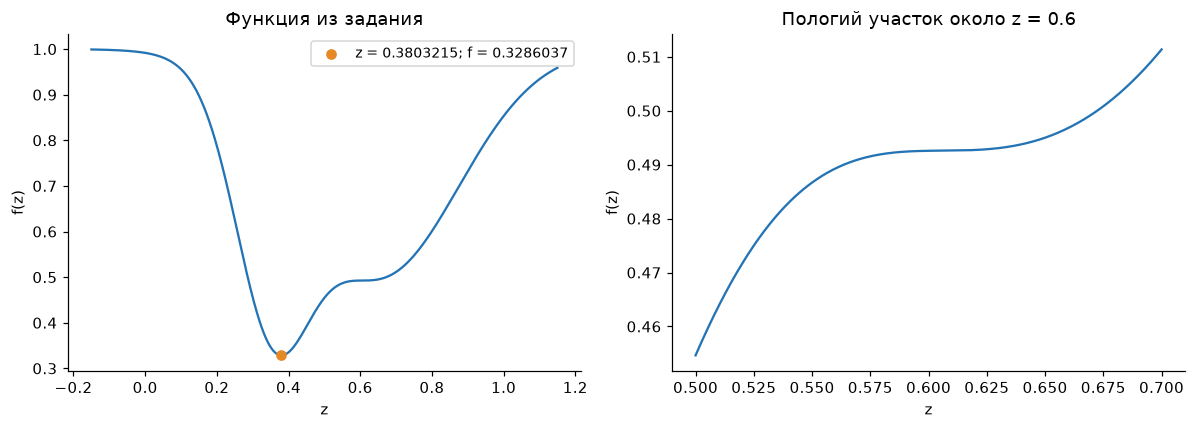

Глобальный минимум: z ≈ 0.38032153, f(z) ≈ 0.3286036575


In [2]:
roots = np.roots([80., -18., -1.8, .3])
critical = np.sort(roots[(np.abs(roots.imag) < 1e-12) & (roots.real > 0) & (roots.real < .3)].real)
H = lambda t: np.log(4.5*t / (.3-t)) - 50*t**2 + 10*(t-.3)**2
certificate = pd.DataFrame({'t': critical, 'H(t)': H(critical)})
assert len(critical) == 2 and (H(critical) > 0).all()
display(certificate)
minimum = golden_section(target_function, 0., 1., tolerance=1e-10)
minimum_table = pd.DataFrame([{
    'z_min': minimum.x, 'f_min': minimum.fun,
    'left': minimum.left, 'right': minimum.right,
    'interval_width': minimum.right - minimum.left,
    'iterations': minimum.iterations, 'function_evaluations': minimum.evaluations}])
display(minimum_table)
minimum_table.to_csv(RESULT_DIR / 'minimum.csv', index=False)
certificate.to_csv(RESULT_DIR / 'unimodality.csv', index=False)

z = np.linspace(-.15, 1.15, 1301)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(z, target_function(z), color='#2474b5')
axes[0].scatter([minimum.x], [minimum.fun], color='#e48925', zorder=3,
                label=f'z = {minimum.x:.7f}; f = {minimum.fun:.7f}')
axes[0].set(xlabel='z', ylabel='f(z)', title='Функция из задания')
axes[0].legend(fontsize=9)
zoom = np.linspace(.5, .7, 501)
axes[1].plot(zoom, target_function(zoom), color='#2474b5')
axes[1].set(xlabel='z', ylabel='f(z)', title='Пологий участок около z = 0.6')
show_figure(fig, 'function_minimum.png')
print(f'Глобальный минимум: z ≈ {minimum.x:.8f}, f(z) ≈ {minimum.fun:.10f}')

### 3. Выборка, модели и численные производные

Данные из таблицы задания сохранены в `data.csv`. Использую исходные $x$ и $y$. Рассматриваю ровно три заданные зависимости:

$$\widehat y=w_1x+b_1,$$
$$\widehat y=w_1x^2+w_2x+b_1,$$
$$\widehat y=\operatorname{ReLU}\left(w_{21}\operatorname{ReLU}(w_{11}x+b_{11})
+w_{22}\operatorname{ReLU}(w_{12}x+b_{12})+b_{21}\right).$$

Последняя модель имеет **два скрытых нейрона и ReLU на выходе**.
По сравнению с Lab4 изменены размер входа и выходная активация.

$$J(\theta)=\sum_{i=1}^{12}(y_i-\widehat y(x_i;\theta))^2,$$
$$g_j(\theta)\approx\frac{J(\theta+h_je_j)-J(\theta-h_je_j)}{2h_j},
\qquad h_j=10^{-5}\max(1,|\theta_j|).$$

Один градиент требует $2p$ значений функции: 4, 6 или 14 для трёх моделей.
Векторизация разностей ускоряет вычисления, не заменяя их аналитическими производными.
Для гладкой функции погрешность центральной разности имеет порядок $h^2$
до влияния округления. В точках излома ReLU вычисляется симметричная секущая;
классическая производная там может не существовать.

In [3]:
df = load_data(LAB_DIR / 'data.csv')
x, y = df.x.to_numpy(float), df.y.to_numpy(float)
display(df)
print('Наблюдений:', len(x), '; пропусков:', int(df.isna().sum().sum()))
display(pd.DataFrame([{'model': model, 'parameters': ', '.join(PARAMETERS[model]),
                      'count': len(PARAMETERS[model])} for model in MODELS]))
display(pd.DataFrame(LEARNING_RATES).T.rename_axis('model'))

,x,y
0,0.03,0.67
1,0.19,0.85
2,0.34,1.05
3,0.46,1
4,0.78,1.4
5,0.81,1.5
6,1.08,1.3
7,1.18,1.54
8,1.39,1.55
9,1.6,1.68


Наблюдений: 12 ; пропусков: 0


,model,parameters,count
0,linear,"w1, b1",2
1,quadratic,"w1, w2, b1",3
2,relu,"w11, b11, w12, b12, w21, w22, b21",7


,gd,sgd,nesterov,adam
model,,,,
linear,0.02,0.005,0.01,0.02
quadratic,0.01,0.0025,0.01,0.02
relu,0.01,0.005,0.01,0.02


#### Условия эксперимента

Для классического GD использую постоянный шаг и всю выборку:
$\theta_{k+1}=\theta_k-\eta g(\theta_k)$. Для линейной модели $\eta=0.02$,
для квадратичной и сети $\eta=0.01$. Все шаги остальных методов указаны в таблице выше.
Они выбраны как устойчивые настройки и не являются результатом подбора.

Для всех методов лимит равен 3000 эпох. После каждой эпохи проверяю
$\|g_{\mathrm{full}}\|_\infty<10^{-5}$. Достижение лимита не считается сходимостью.
Для ReLU это критерий численной стационарности при выбранном разностном шаге.
Каждый эксперимент повторяю с `seed=2026,2027,2028`.
Начальные параметры при фиксированных модели и seed одинаковы для всех
методов, размеров батча и значений штрафа; порядок минибатчей также парный.

Полиномиальные коэффициенты начинаются из $[-0.1,0.1]$.
Для сети к $(1,-0.35,-1,1.3,0.25,0.25,0.5)$ добавляется шум из $[-0.04,0.04]$.
Так скрытые нейроны имеют изломы внутри диапазона данных, а выход изначально активен.
Это снижает риск попадания в область с неактивными ReLU; результат сети всё равно
зависит от инициализации. Полная таблица начальных параметров сохраняется отдельно.

Следующая ячейка **пересчитывает все 351 запуска**, включая регуляризацию из задачи 5*.

Кривые прогнозов и обучения ниже относятся к `seed=2026`. Средние значения,
стандартные отклонения и интервалы на графике размеров батча вычислены по всем трём seed.

In [4]:
MAX_EPOCHS = 3000
training, history, parameters = run_experiments(LAB_DIR, max_epochs=MAX_EPOCHS)
summary = pd.read_csv(RESULT_DIR / 'summary.csv')
reference = pd.read_csv(RESULT_DIR / 'reference.csv')
assert len(training) == 3 * 3 * 3 * (1 + 3 * 4) == 351
print('Всего запусков:', len(training), '; критерий выполнен:', int(training.converged.sum()))

def selected(model, method, batch=12, l2=0., seed=2026):
    rows = training[(training.model == model) & (training.method == method)
                    & (training.batch_size == batch) & (training.l2 == l2) & (training.seed == seed)]
    if len(rows) != 1:
        raise ValueError('Неоднозначный выбор эксперимента')
    row = rows.iloc[0]
    values = parameters[parameters.run_id == row.run_id].set_index('parameter').value
    theta = values.reindex(PARAMETERS[model]).to_numpy(float)
    return row, theta

gd = training[(training.method == 'gd') & (training.l2 == 0) & (training.seed == 2026)]
display(gd[['model', 'epochs', 'updates', 'SSE', 'RMSE', 'R2', 'gradient_inf', 'converged']])
for model in MODELS:
    row, theta = selected(model, 'gd')
    display(pd.DataFrame({'parameter': PARAMETERS[model], 'value': theta}))

linear, lambda=0, seed=2026: завершено 13 запусков


linear, lambda=0, seed=2027: завершено 26 запусков


linear, lambda=0, seed=2028: завершено 39 запусков


linear, lambda=0.1, seed=2026: завершено 52 запусков


linear, lambda=0.1, seed=2027: завершено 65 запусков


linear, lambda=0.1, seed=2028: завершено 78 запусков


... (22 outputs left out)

,model,epochs,updates,SSE,RMSE,R2,gradient_inf,converged
0,linear,133,133,0.1998664,0.1290563,0.8503126,9.9539e-06,True
117,quadratic,2510,2510,0.09088204,0.08702588,0.931935,9.964948e-06,True
234,relu,3000,3000,0.07879874,0.08103432,0.9409847,0.005403551,False


,parameter,value
0,w1,0.5222283
1,b1,0.8259476


,parameter,value
0,w1,-0.318135
1,w2,1.126767
2,b1,0.6491219


,parameter,value
0,w11,1.017016
1,b11,0.1309888
2,w12,-1.315497
3,b12,1.064685
4,w21,0.2460856
5,w22,-0.5208279
6,b21,1.180569


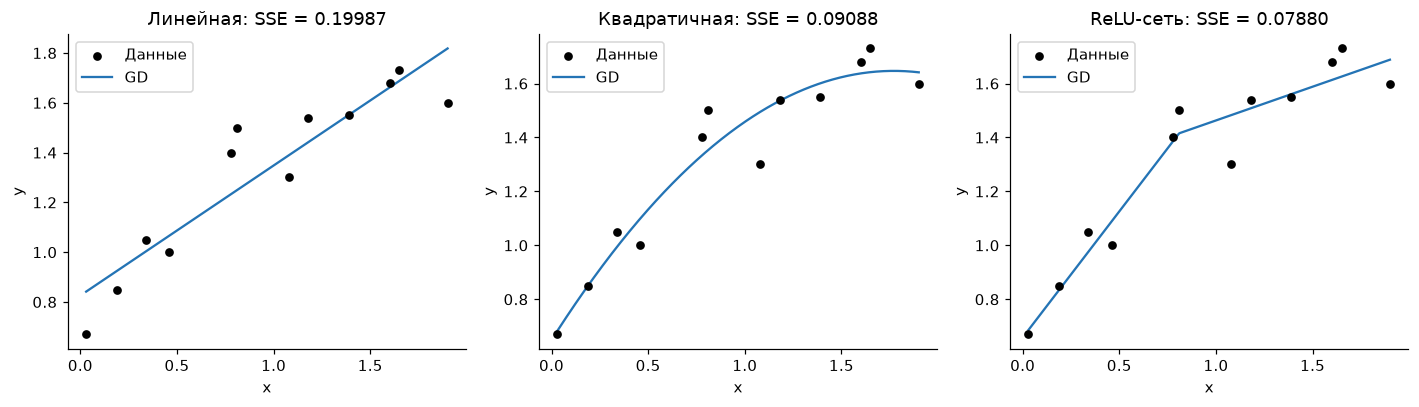

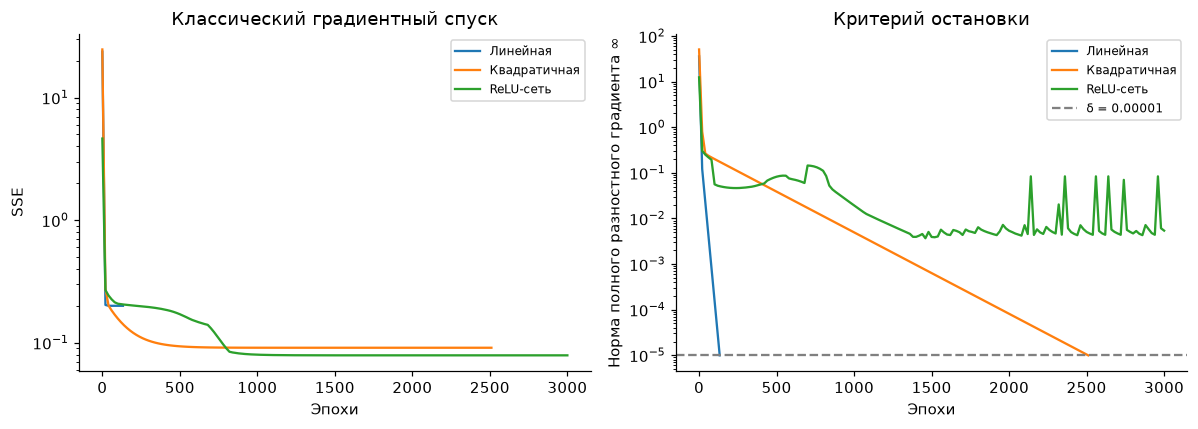

In [5]:
grid = np.linspace(x.min(), x.max(), 400)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, model in zip(axes, MODELS):
    row, theta = selected(model, 'gd')
    ax.scatter(x, y, color='black', s=22, label='Данные', zorder=3)
    ax.plot(grid, predict(grid, theta, model), color='#2474b5', label='GD')
    ax.set(xlabel='x', ylabel='y', title=f'{LABELS[model]}: SSE = {row.SSE:.5f}')
    ax.legend()
show_figure(fig, 'gd_fits.png')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for model in MODELS:
    row, _ = selected(model, 'gd')
    h = history[history.run_id == row.run_id]
    axes[0].semilogy(h.epoch, h.SSE, label=LABELS[model])
    axes[1].semilogy(h.epoch, h.gradient_inf, label=LABELS[model])
axes[0].set(xlabel='Эпохи', ylabel='SSE', title='Классический градиентный спуск')
axes[1].set(xlabel='Эпохи', ylabel='Норма полного разностного градиента ∞', title='Критерий остановки')
axes[1].axhline(1e-5, color='gray', linestyle='--', label='δ = 0.00001')
for ax in axes:
    ax.legend(fontsize=8)
show_figure(fig, 'gd_learning.png')

#### Проверка полиномиальных моделей и точности разностей

Отдельно решаю задачу МНК. Для контроля используется
`numpy.linalg.lstsq`; эти коэффициенты не подаются в градиентный спуск.
Для сети такого эталона нет. Сравниваю SSE с эталоном и проверяю,
насколько меняется разностный градиент при $h=10^{-4},10^{-5},10^{-6}$.

In [6]:
controls, sensitivity = [], []
for model in MODELS:
    row, theta = selected(model, 'gd')
    if model != 'relu':
        ref = reference_solution(x, y, model)
        ref_sse = float(objective(ref, x, y, model))
        controls.append({'model': model, 'SSE_GD': row.SSE, 'SSE_OLS': ref_sse,
                         'SSE_gap': row.SSE - ref_sse,
                         'max_parameter_difference': np.max(np.abs(theta - ref))})
    gradients = [numerical_gradient(lambda t: objective(t, x, y, model), theta,
                                   relative_step=step) for step in (1e-4, 1e-5, 1e-6)]
    for step, gradient in zip((1e-4, 1e-5, 1e-6), gradients):
        sensitivity.append({'model': model, 'relative_step': step,
                            'gradient_inf': np.max(np.abs(gradient)),
                            'difference_from_h1e5': np.max(np.abs(gradient - gradients[1]))})
control_table, sensitivity_table = pd.DataFrame(controls), pd.DataFrame(sensitivity)
display(control_table)
display(sensitivity_table)
control_table.to_csv(RESULT_DIR / 'gd_control.csv', index=False)
sensitivity_table.to_csv(RESULT_DIR / 'difference_step_check.csv', index=False)
display(Markdown('Для МНК получено **SSE = 0.19986636** у прямой и **0.09088204** у параболы. '
                 'Насколько GD приблизился к этим значениям, видно по `SSE_gap`; '
                 'малое расхождение с эталоном не заменяет проверки `converged`. '
                 f'Для сети GD при seed=2026 даёт **SSE = {selected("relu", "gd")[0].SSE:.8f}**. '
                 'Сопоставление описывает подгонку 12 исходных точек.'))

,model,SSE_GD,SSE_OLS,SSE_gap,max_parameter_difference
0,linear,0.1998664,0.1998664,2.193581e-11,2.492108e-06
1,quadratic,0.09088204,0.09088204,1.643945e-10,2.428841e-05


,model,relative_step,gradient_inf,difference_from_h1e5
0,linear,0.0001,9.953898e-06,7.077672e-12
1,linear,1e-05,9.9539e-06,0
2,linear,1e-06,9.953899e-06,3.747003e-11
3,quadratic,0.0001,9.964947e-06,2.983724e-12
4,quadratic,1e-05,9.964948e-06,0
5,quadratic,1e-06,9.964931e-06,2.775558e-11
6,relu,0.0001,0.005403551,3.122502e-12
7,relu,1e-05,0.005403551,0
8,relu,1e-06,0.005403551,1.637472e-11


Для МНК получено **SSE = 0.19986636** у прямой и **0.09088204** у параболы. Насколько GD приблизился к этим значениям, видно по `SSE_gap`; малое расхождение с эталоном не заменяет проверки `converged`. Для сети GD при seed=2026 даёт **SSE = 0.07879874**. Сопоставление описывает подгонку 12 исходных точек.

#### Результат полного GD

Для прямой критерий достигнут за 133, 134 и 135 эпох; для параболы - за 2510,
2512 и 2521 эпох при seed=2026, 2027 и 2028 соответственно.
Разница с точной целевой функцией МНК меньше $2\cdot10^{-10}$.
Для этих выпуклых моделей численный GD практически воспроизводит решение МНК.

У сети результат существенно зависит от начальной точки:

| Seed | SSE | Эпохи | Норма разностного градиента | Критерий выполнен |
|---:|---:|---:|---:|---|
| 2026 | 0.078799 | 3000 | 0.005404 | Нет |
| 2027 | 0.078797 | 3000 | 0.004848 | Нет |
| 2028 | 0.199866 | 347 | 0.000009 | Да |

Следовательно, малая норма градиента сама по себе не гарантирует лучшей подгонки.
Первые два запуска дали меньшую SSE, но завершились по лимиту, что сохранено в таблице.
Проверка трёх шагов разности в конечной точке seed=2026 меняет градиент меньше
чем на $4\cdot10^{-11}$: в этой точке вывод о невыполненном критерии не объясняется
только выбранным шагом разностей.

### 4. Минибатчи и стохастический градиентный спуск

В начале каждой эпохи случайно переставляю индексы без повторений и разбиваю
их на батчи $B\in\{1,3,6,12\}$. При $B=12$ стохастический шум отсутствует.
Чтобы размеры батча не меняли масштаб целевой функции, дифференцирую

$$\widehat J_B(\theta)=\frac{n}{|B|}\sum_{i\in B}(y_i-\widehat y_i)^2.$$

Для равновероятного батча это несмещённая оценка полной суммы квадратов
в фиксированной точке $\theta$. При перестановках без повторений последующие
батчи зависят от уже просмотренных объектов.

Шаг убывает по эпохам: $\eta_e=\eta_0/(1+e/300)$. Здесь уменьшение шага помогает снизить остаточные колебания.
Начальные шаги SGD равны 0.005, 0.0025 и 0.005 для прямой, параболы и сети.
Меньший шаг квадратичной модели связан с большими значениями $x^2$ в градиенте.
Шумный шаг не обязан уменьшать **полную** SSE; это видно на кривых.

Одна эпоха содержит $12/B$ обновлений. При одинаковом лимите эпох число
просмотренных объектов совпадает, а число обновлений различается в 12 раз.
В `derivative_sample_evaluations` учтены $2p$ разностных вычислений по объектам,
включая полный контрольный градиент после каждой эпохи. Это счётчик работы
с производными, а не замер времени и не число всех служебных вычислений.

,model,batch_size,SSE_mean,SSE_std,SSE_min,SSE_max,converged_runs,updates_mean
27,linear,1,0.1998818,1.559857e-05,0.1998689,0.1998991,0,36000
30,linear,3,0.1998675,1.431962e-06,0.1998665,0.1998691,0,12000
33,linear,6,0.1998664,2.211644e-08,0.1998664,0.1998664,0,6000
36,linear,12,0.1998664,4.640057e-14,0.1998664,0.1998664,3,1608
66,quadratic,1,0.09088913,6.824562e-06,0.09088301,0.09089649,0,36000
69,quadratic,3,0.0912682,1.823925e-05,0.0912552,0.09128905,0,12000
72,quadratic,6,0.09891696,0.0004036171,0.09863234,0.09937888,0,6000
75,quadratic,12,0.1266758,0.001836705,0.1253593,0.1287741,0,3000
105,relu,1,0.07880257,2.950767e-06,0.07880012,0.07880585,0,36000
108,relu,3,0.0788953,0.0001546975,0.0788046,0.07907392,0,12000


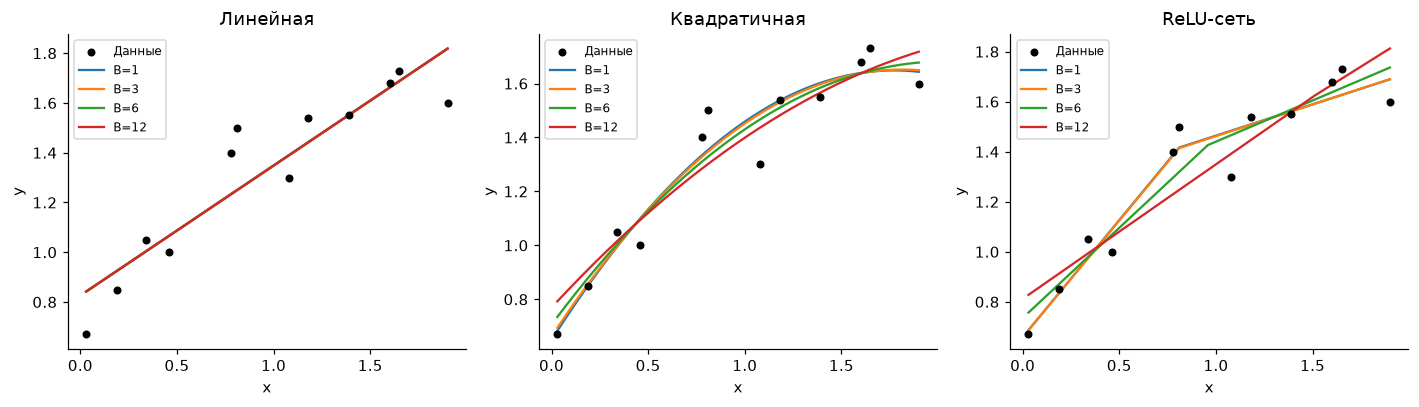

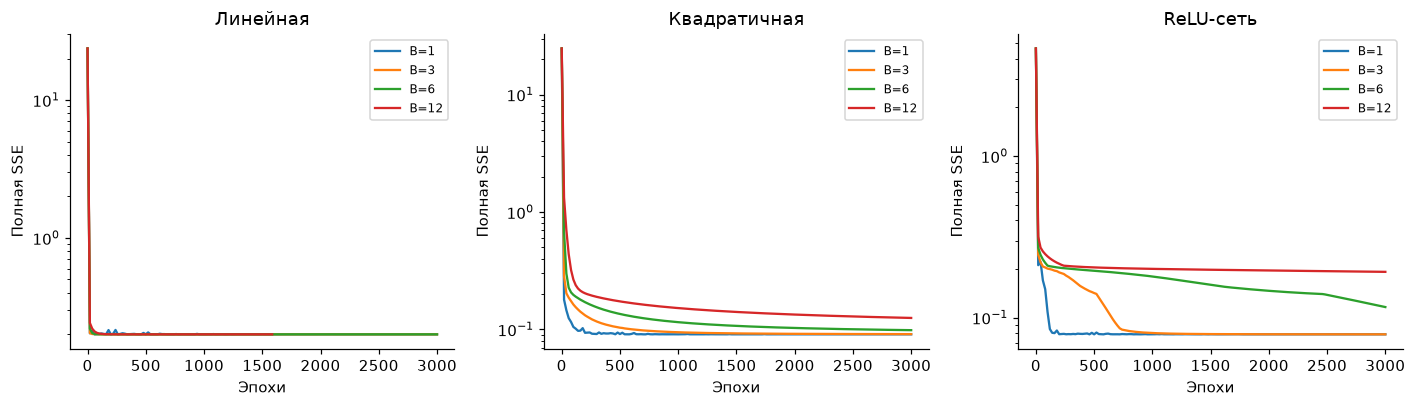

Линейная: минимальная средняя SSE у SGD при B=12: 0.1998664 +- 0.0000000 (стандартное отклонение трёх запусков).
Квадратичная: минимальная средняя SSE у SGD при B=1: 0.0908891 +- 0.0000068 (стандартное отклонение трёх запусков).
ReLU-сеть: минимальная средняя SSE у SGD при B=1: 0.0788026 +- 0.0000030 (стандартное отклонение трёх запусков).


In [7]:
sgd_summary = summary[(summary.method == 'sgd') & (summary.l2 == 0)]
display(sgd_summary[['model', 'batch_size', 'SSE_mean', 'SSE_std', 'SSE_min', 'SSE_max',
                     'converged_runs', 'updates_mean']])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, model in zip(axes, MODELS):
    ax.scatter(x, y, color='black', s=18, label='Данные', zorder=3)
    for batch in BATCH_SIZES:
        row, theta = selected(model, 'sgd', batch)
        ax.plot(grid, predict(grid, theta, model), label=f'B={batch}')
    ax.set(xlabel='x', ylabel='y', title=LABELS[model])
    ax.legend(fontsize=8)
show_figure(fig, 'sgd_fits.png')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, model in zip(axes, MODELS):
    for batch in BATCH_SIZES:
        row, _ = selected(model, 'sgd', batch)
        h = history[history.run_id == row.run_id]
        ax.semilogy(h.epoch, h.SSE, label=f'B={batch}')
    ax.set(xlabel='Эпохи', ylabel='Полная SSE', title=LABELS[model])
    ax.legend(fontsize=8)
show_figure(fig, 'sgd_learning.png')
for model in MODELS:
    subset = sgd_summary[sgd_summary.model == model]
    best = subset.loc[subset.SSE_mean.idxmin()]
    print(f'{LABELS[model]}: минимальная средняя SSE у SGD при B={int(best.batch_size)}: '
          f'{best.SSE_mean:.7f} +- {best.SSE_std:.7f} (стандартное отклонение трёх запусков).')

При малых батчах за эпоху выполняется больше обновлений, но градиенты отдельных
точек сильнее различаются. Для этой маленькой выборки лучше всего сравнивать
одновременно конечную SSE, разброс по seed и траекторию полной ошибки.
Убывающий шаг уменьшает колебания, но к концу они могут сохраняться. Преимущество конкретного размера батча при этих настройках не является общей закономерностью.

В полученных данных SGD для параболы с B=1 даёт среднюю SSE **0.090889**,
с B=12 - **0.126676**. При лимите 3000 эпох это 36 000 и 3000 обновлений:
у меньшего батча больше возможностей продвинуться вдоль плохо обусловленного направления.
Для прямой различия малы: с ростом B уменьшаются и ошибка, и её разброс.
Для сети SGD с B=1 даёт **0.078803**, с B=12 - **0.195169**; у B=6 заметен
разброс между seed (SD около **0.0440**). Таким образом, эффект батча связан
с числом шагов, остаточным шумом и выбором области активации сети.

### 5. Импульс Нестерова и Adam

Использую нормировку импульса:

$$q_k=\theta_k-\eta_e\beta m_k,\quad
m_{k+1}=\beta m_k+(1-\beta)g_B(q_k),\quad
\theta_{k+1}=\theta_k-\eta_e m_{k+1},\qquad\beta=0.9.$$

Начальный импульс нулевой. Градиент считается в предполагаемой точке $q_k$.
Множитель $(1-\beta)$ отличает принятую запись от варианта с ненормированной скоростью.

Для Adam:

$$m_k=\beta m_{k-1}+(1-\beta)g_k,\quad
v_k=\gamma v_{k-1}+(1-\gamma)g_k^2,$$
$$\widehat m_k=\frac{m_k}{1-\beta^k},\quad
\widehat v_k=\frac{v_k}{1-\gamma^k},\quad
\theta_{k+1}=\theta_k-\eta_e\frac{\widehat m_k}{\sqrt{\widehat v_k}+\epsilon}.$$

Здесь $k$ - номер **обновления**, а не эпохи; $\gamma=0.999$,
$\epsilon=10^{-8}$. Все операции с $v$ поэлементные.
Начальный шаг Нестерова 0.01, Adam 0.02. Все методы используют одинаковую численную производную и масштаб суммы квадратов.
Начальные шаги отличаются, поэтому сравнение характеризует указанные настройки методов.

На графиках прямого сравнения методов использую B=3 для SGD, Нестерова и Adam
и B=12 для полного GD. Все четыре размера батча сопоставлены в таблицах
и на отдельном графике средних SSE с SD.

method                     adam         gd   nesterov        sgd
model     batch_size                                            
linear    1           0.1999166        NaN  0.2000373  0.1998818
          3           0.1998699        NaN  0.1998692  0.1998675
          6           0.1998679        NaN  0.1998664  0.1998664
          12          0.1998664  0.1998664  0.1998664  0.1998664
quadratic 1           0.0911057        NaN 0.09111871 0.09088913
          3          0.09096164        NaN 0.09089885  0.0912682
          6          0.09088976        NaN 0.09088508 0.09891696
          12         0.09263879 0.09088204 0.09130647  0.1266758
relu      1          0.07893575        NaN 0.07885331 0.07880257
          3           0.1998791        NaN 0.07880069  0.0788953
          6            0.199879        NaN 0.07880548  0.1501541
          12          0.1998664  0.1191541  0.0994323  0.1951694

,model,method,batch_size,SSE_mean,SSE_std,gradient_mean,converged_runs
0,linear,adam,1,0.1999166,4.717817e-05,0.0478019,0
3,linear,adam,3,0.1998699,4.453787e-06,0.01143614,0
6,linear,adam,6,0.1998679,6.899672e-07,0.009345904,0
9,linear,adam,12,0.1998664,1.763526e-13,9.972865e-06,3
12,linear,gd,12,0.1998664,3.728737e-13,9.858349e-06,3
15,linear,nesterov,1,0.2000373,0.000125189,0.0909545,0
18,linear,nesterov,3,0.1998692,3.461309e-06,0.01034127,0
21,linear,nesterov,6,0.1998664,6.836622e-08,0.001447183,0
24,linear,nesterov,12,0.1998664,2.932005e-13,9.731783e-06,3
27,linear,sgd,1,0.1998818,1.559857e-05,0.02414492,0


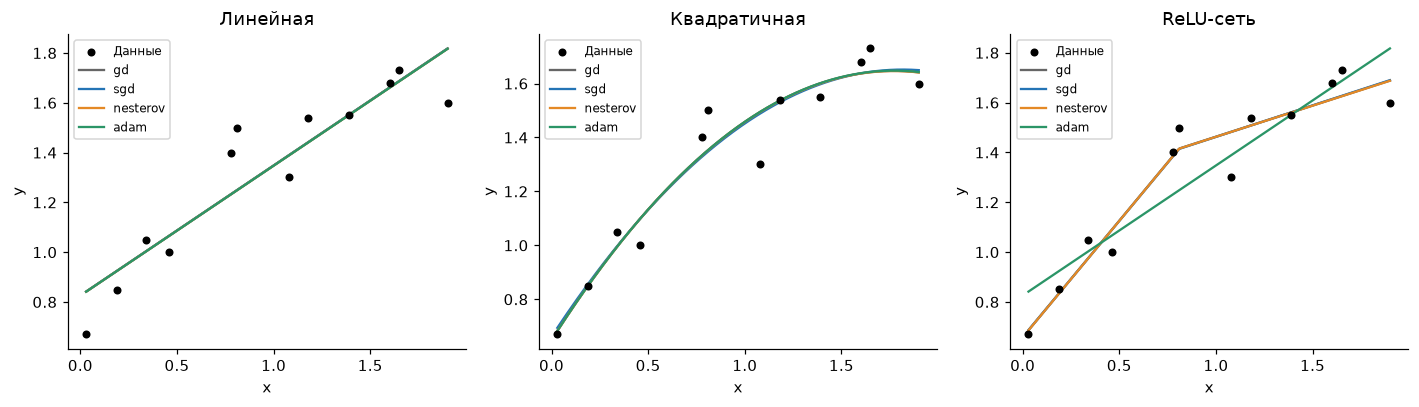

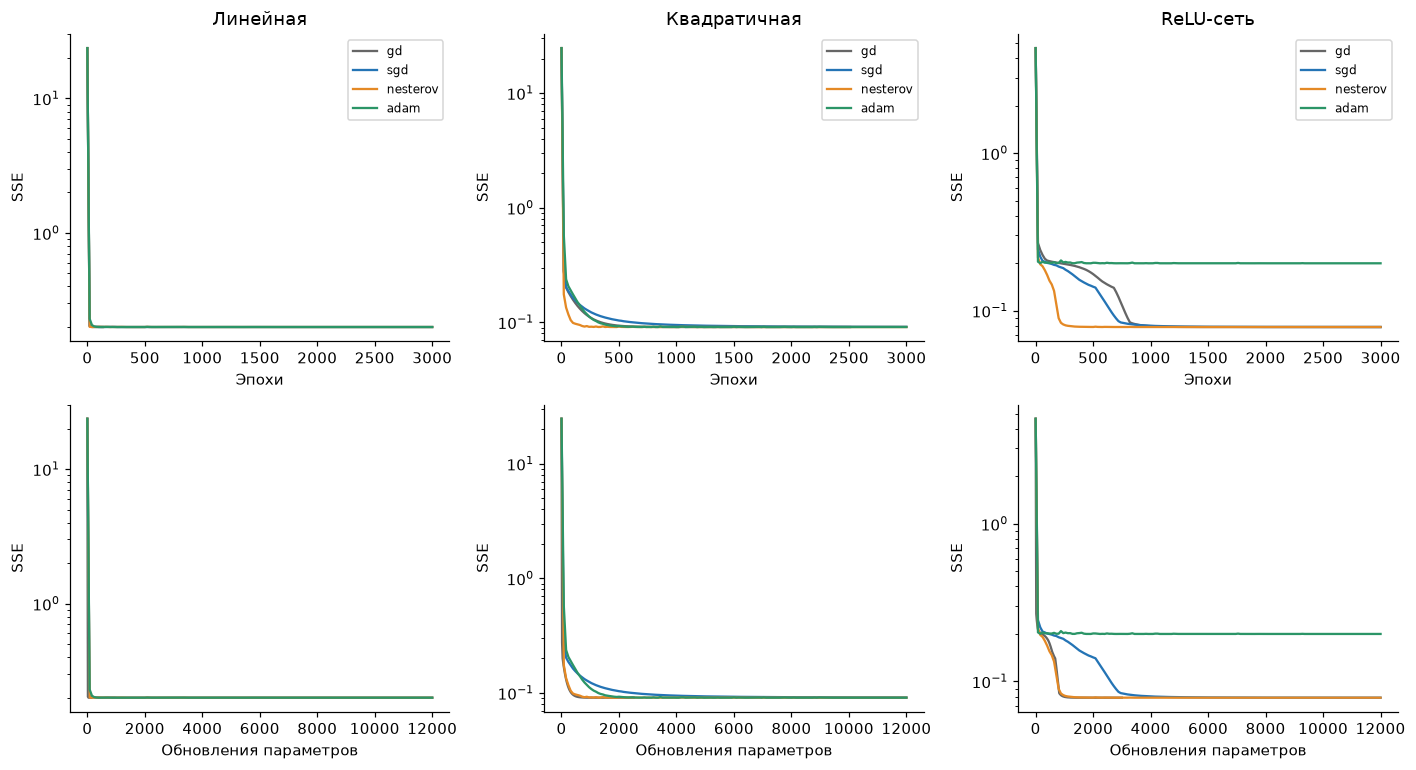

In [8]:
base = summary[summary.l2 == 0]
display(base.pivot_table(index=['model', 'batch_size'], columns='method', values='SSE_mean'))
display(base[['model', 'method', 'batch_size', 'SSE_mean', 'SSE_std', 'gradient_mean', 'converged_runs']])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, model in zip(axes, MODELS):
    ax.scatter(x, y, color='black', s=18, label='Данные', zorder=3)
    for method in METHODS:
        batch = 12 if method == 'gd' else 3
        row, theta = selected(model, method, batch)
        ax.plot(grid, predict(grid, theta, model), color=COLORS[method], label=method)
    ax.set(xlabel='x', ylabel='y', title=LABELS[model])
    ax.legend(fontsize=8)
show_figure(fig, 'optimizer_fits.png')

fig, axes = plt.subplots(2, 3, figsize=(13, 7.1))
for j, model in enumerate(MODELS):
    for method in METHODS:
        batch = 12 if method == 'gd' else 3
        row, _ = selected(model, method, batch)
        h = history[history.run_id == row.run_id]
        axes[0, j].semilogy(h.epoch, h.SSE, color=COLORS[method], label=method)
        # Одинаковая ось числа обновлений показывает различие бюджета методов.
        axes[1, j].semilogy(h.updates, h.SSE, color=COLORS[method], label=method)
    axes[0, j].set(xlabel='Эпохи', ylabel='SSE', title=LABELS[model])
    axes[1, j].set(xlabel='Обновления параметров', ylabel='SSE')
    axes[0, j].legend(fontsize=8)
show_figure(fig, 'optimizer_learning.png')

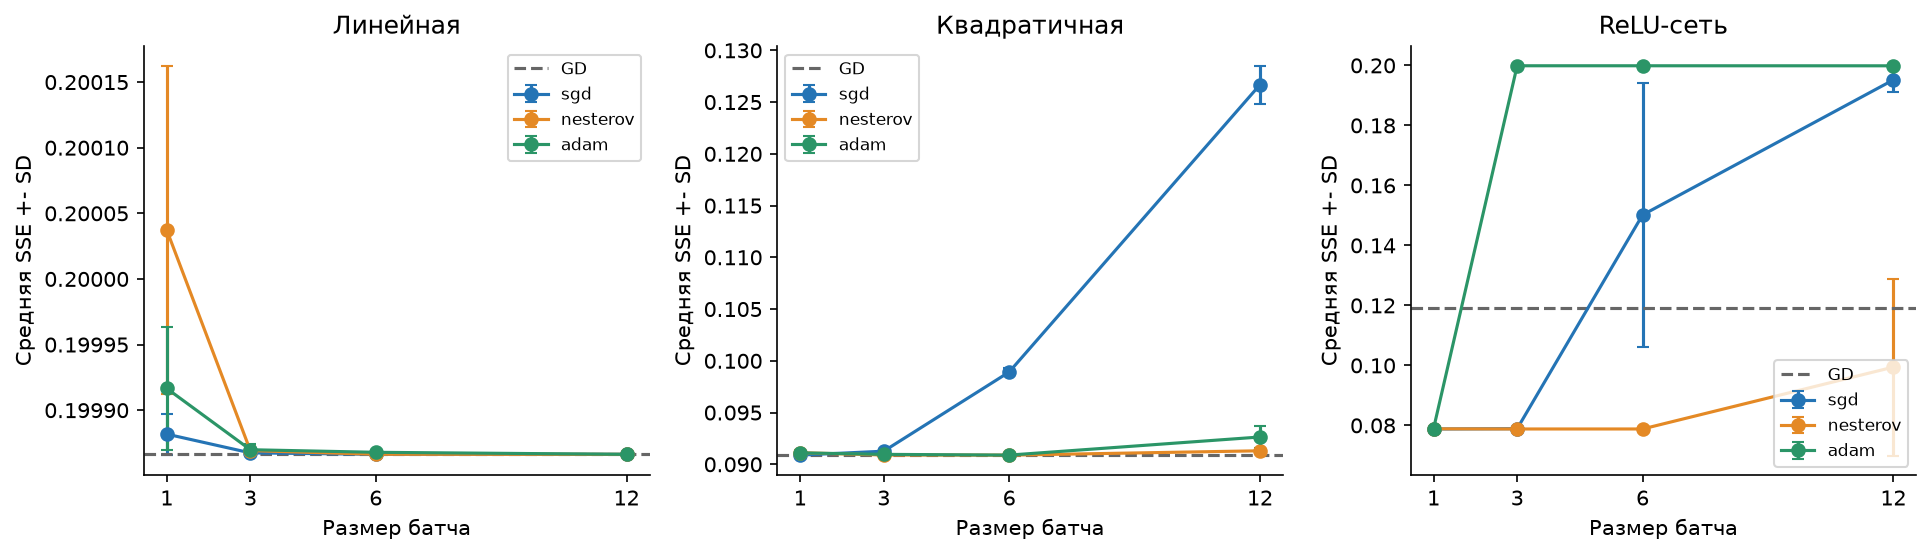

**Линейная:** наименьшая средняя SSE **0.1998664** у `gd`, B=12; разброс SD = 0.0000000. Критерий выполнен в 3 из 3 повторов этой конфигурации.

**Квадратичная:** наименьшая средняя SSE **0.0908820** у `gd`, B=12; разброс SD = 0.0000000. Критерий выполнен в 3 из 3 повторов этой конфигурации.

**ReLU-сеть:** наименьшая средняя SSE **0.0788007** у `nesterov`, B=3; разброс SD = 0.0000020. Критерий выполнен в 0 из 3 повторов этой конфигурации.

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, model in zip(axes, MODELS):
    for method in ('sgd', 'nesterov', 'adam'):
        s = base[(base.model == model) & (base.method == method)].sort_values('batch_size')
        ax.errorbar(s.batch_size, s.SSE_mean, yerr=s.SSE_std, marker='o', capsize=3,
                    color=COLORS[method], label=method)
    gd_mean = base[(base.model == model) & (base.method == 'gd')].SSE_mean.iloc[0]
    ax.axhline(gd_mean, color=COLORS['gd'], linestyle='--', label='GD')
    ax.set(xlabel='Размер батча', ylabel='Средняя SSE +- SD', title=LABELS[model], xticks=BATCH_SIZES)
    ax.legend(fontsize=8)
show_figure(fig, 'batch_comparison.png')

for model in MODELS:
    s = base[base.model == model]
    best = s.loc[s.SSE_mean.idxmin()]
    display(Markdown(f'**{LABELS[model]}:** наименьшая средняя SSE **{best.SSE_mean:.7f}** '
                     f'у `{best.method}`, B={int(best.batch_size)}; '
                     f'разброс SD = {best.SSE_std:.7f}. '
                     f'Критерий выполнен в {int(best.converged_runs)} из 3 повторов этой конфигурации.'))

Нестеров сглаживает последовательность градиентов и учитывает их в предсказанной точке;
Adam дополнительно нормирует координаты с поправкой начального смещения моментов.
У сети активации может меняться область линейности, и оптимизаторы могут прийти
к разным локальным решениям. Меньшая конечная SSE не доказывает более быстрой
сходимости на других данных. Три повтора показывают наблюдаемый разброс,
но не дают надёжной статистической оценки распределения результатов.

Для параболы полный GD даёт среднюю SSE **0.0908820**, Нестеров с B=6 -
**0.0908851**, Adam с B=6 - **0.0908898**. При выбранном бюджете ускоряющие
методы не дали ошибки ниже достигнутого решения МНК.
Для сети Нестеров с B=3 даёт **0.0788007 +- 0.0000020**, а Adam с тем же B=3 -
**0.1998791 +- 0.0000145** (среднее +- SD трёх seed).

У сохранённой сети Adam, B=3, seed=2026 оба скрытых входа положительны
на всём отрезке наблюдений: первый меняется от **0.004274** до **2.234585**,
второй - от **0.006535** до **1.217973**; выход также положителен.
На этом отрезке все ReLU действуют как тождественные преобразования,
поэтому прогноз этой сети является прямой. Это объясняет её ошибку около
линейного эталона и различие с кусочно-линейной подгонкой Нестерова.
Универсального преимущества Adam эти эксперименты не показывают.

### 6. Задача 5*. Квадратичный штраф

Повторяю задачи 2-4 при $\lambda\in\{0.1,1\}$ и сравниваю с $\lambda=0$:

$$J_\lambda(\theta)=J(\theta)+\lambda\sum_{j\in\mathrm{weights}}\theta_j^2.$$

Штрафую только веса: $w_1$ у прямой; $w_1,w_2$ у параболы;
$w_{11},w_{12},w_{21},w_{22}$ у сети. Смещения в штраф не входят.
Для минибатча используется $n/|B|\cdot\mathrm{SSE}_B+\lambda R$:
штраф добавляется **один раз** к стохастической оценке полной цели.
Он включён внутрь численного дифференцирования; это L2-штраф, в том числе для Adam.

Показываю отдельно SSE, значение $J_\lambda$ и евклидову норму весов.
Значения $J_\lambda$ с разными $\lambda$ относятся к разным целевым функциям
и не служат общей шкалой качества. Для полиномов вычисляю контрольное ridge-решение
$\theta=(A^TA+\lambda D)^{-1}A^Ty$, где $D$ имеет нули для смещений.

,model,method,batch_size,l2,SSE_mean,SSE_std,objective_mean,weight_norm_mean,converged_runs
3,linear,adam,3,0,0.1998699,4.453787e-06,0.1998699,0.5219565,0
4,linear,adam,3,0.1,0.2005195,3.29312e-05,0.2265019,0.5097297,0
5,linear,adam,3,1,0.2425062,0.0003777721,0.4197686,0.4210253,0
12,linear,gd,12,0,0.1998664,3.728737e-13,0.1998664,0.5222282,3
13,linear,gd,12,0.1,0.2004909,7.849631e-09,0.2264986,0.5099782,3
14,linear,gd,12,1,0.2424556,4.212108e-08,0.4197653,0.4210817,3
18,linear,nesterov,3,0,0.1998692,3.461309e-06,0.1998692,0.5219321,0
19,linear,nesterov,3,0.1,0.2005203,2.776801e-05,0.2265012,0.509715,0
20,linear,nesterov,3,1,0.2424989,0.000311563,0.4197679,0.4210331,0
30,linear,sgd,3,0,0.1998675,1.431962e-06,0.1998675,0.5219172,0


,model,l2,SSE,objective_GD,objective_exact,objective_gap
0,linear,0,0.1998664,0.1998664,0.1998664,2.193587e-11
1,linear,0.1,0.2004909,0.2264986,0.2264986,1.906597e-11
2,linear,1,0.2424556,0.4197653,0.4197653,1.498418e-11
3,quadratic,0,0.09088204,0.09088204,0.09088204,1.643945e-10
4,quadratic,0.1,0.1191715,0.1870417,0.1870417,1.145189e-10
5,quadratic,1,0.2906769,0.377787,0.377787,3.037287e-11


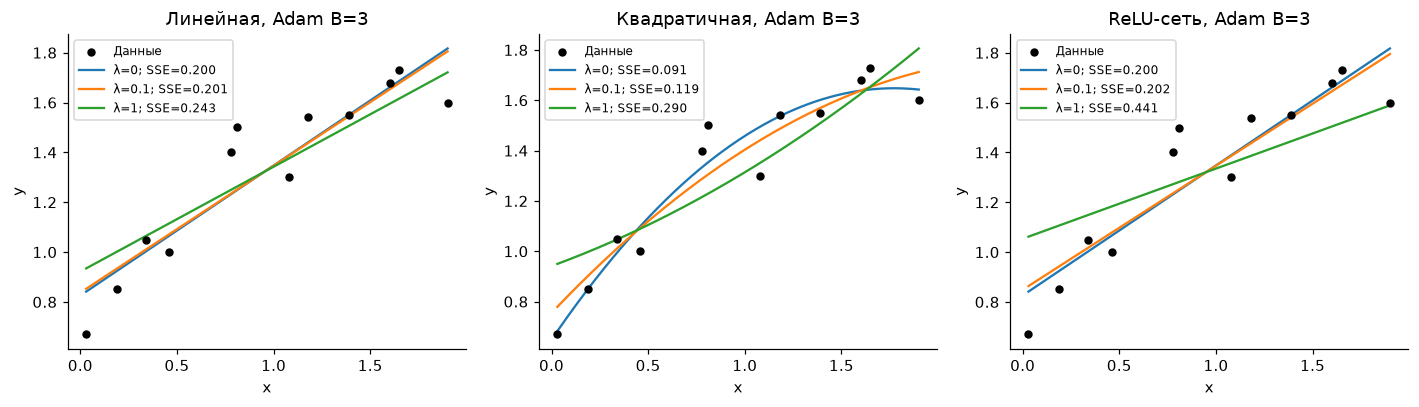

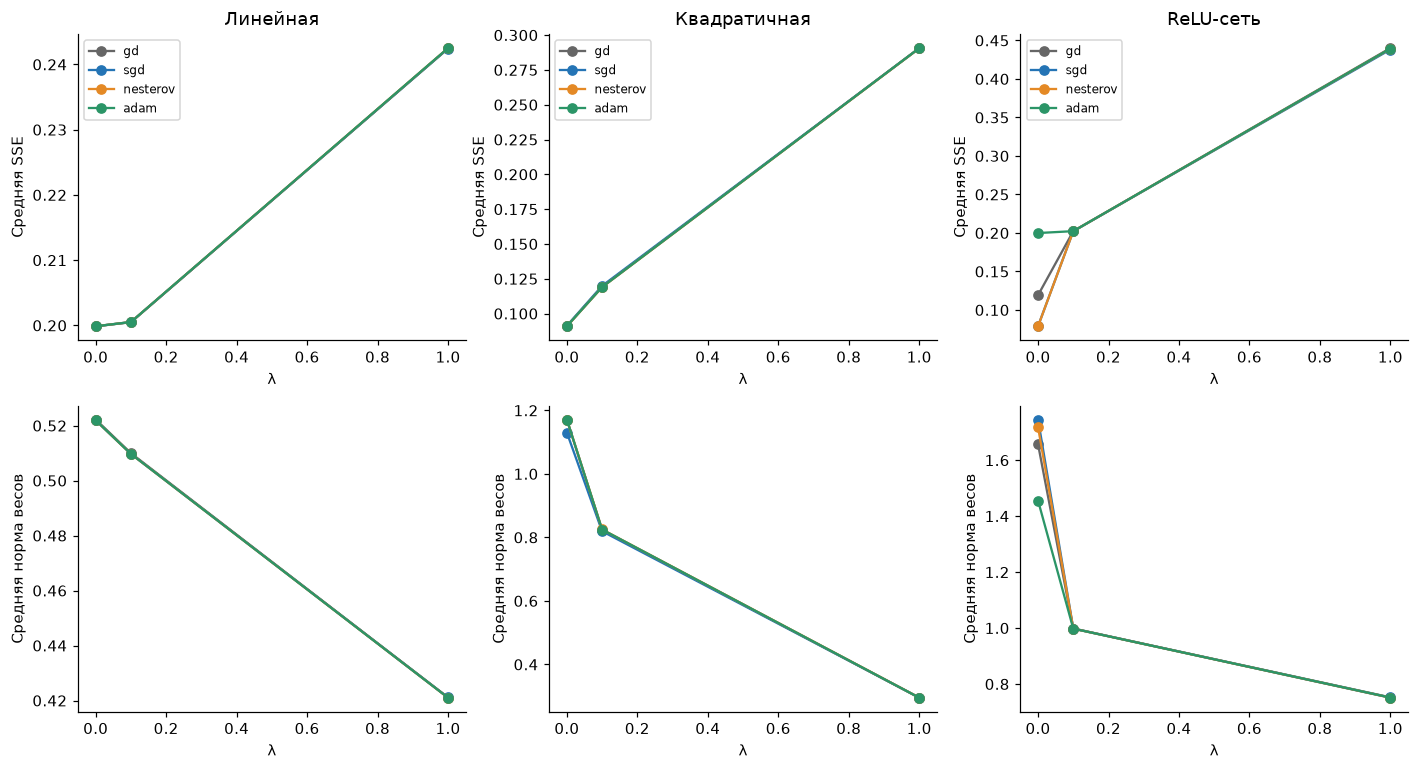

Линейная, Adam B=3: SSE [0.19987, 0.200519, 0.242506], нормы весов [0.521957, 0.50973, 0.421025] при λ=[0.0, 0.1, 1.0]
Квадратичная, Adam B=3: SSE [0.090962, 0.119031, 0.290589], нормы весов [1.17119, 0.824804, 0.295297] при λ=[0.0, 0.1, 1.0]
ReLU-сеть, Adam B=3: SSE [0.199879, 0.202337, 0.439386], нормы весов [1.455798, 0.997944, 0.751491] при λ=[0.0, 0.1, 1.0]


In [10]:
regularization = summary[((summary.method == 'gd') & (summary.batch_size == 12))
                         | ((summary.method != 'gd') & (summary.batch_size == 3))]
display(regularization[['model', 'method', 'batch_size', 'l2', 'SSE_mean', 'SSE_std',
                        'objective_mean', 'weight_norm_mean', 'converged_runs']])
gd_check = training[(training.method == 'gd') & (training.seed == 2026) & (training.model != 'relu')]
ridge_check = gd_check.merge(reference[['model', 'l2', 'objective']], on=['model', 'l2'], suffixes=('_GD', '_exact'))
ridge_check['objective_gap'] = ridge_check.objective_GD - ridge_check.objective_exact
display(ridge_check[['model', 'l2', 'SSE', 'objective_GD', 'objective_exact', 'objective_gap']])
ridge_check.to_csv(RESULT_DIR / 'ridge_control.csv', index=False)
regularization.to_csv(RESULT_DIR / 'regularization_comparison.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, model in zip(axes, MODELS):
    ax.scatter(x, y, color='black', s=20, label='Данные', zorder=3)
    for l2 in PENALTIES:
        row, theta = selected(model, 'adam', 3, l2)
        ax.plot(grid, predict(grid, theta, model), label=f'λ={l2:g}; SSE={row.SSE:.3f}')
    ax.set(xlabel='x', ylabel='y', title=f'{LABELS[model]}, Adam B=3')
    ax.legend(fontsize=8)
show_figure(fig, 'regularized_fits.png')

fig, axes = plt.subplots(2, 3, figsize=(13, 7.1))
for j, model in enumerate(MODELS):
    for method in METHODS:
        s = regularization[(regularization.model == model) & (regularization.method == method)].sort_values('l2')
        axes[0, j].plot(s.l2, s.SSE_mean, marker='o', color=COLORS[method], label=method)
        axes[1, j].plot(s.l2, s.weight_norm_mean, marker='o', color=COLORS[method], label=method)
    axes[0, j].set(xlabel='λ', ylabel='Средняя SSE', title=LABELS[model])
    axes[1, j].set(xlabel='λ', ylabel='Средняя норма весов')
    axes[0, j].legend(fontsize=8)
show_figure(fig, 'regularization_effect.png')
for model in MODELS:
    s = regularization[(regularization.model == model) & (regularization.method == 'adam')].sort_values('l2')
    print(f'{LABELS[model]}, Adam B=3: SSE {s.SSE_mean.round(6).to_list()}, '
          f'нормы весов {s.weight_norm_mean.round(6).to_list()} при λ={list(PENALTIES)}')

L2-штраф ограничивает веса ценой изменения подгонки. У точного выпуклого решения
при росте штрафа норма весов не возрастает, а минимальная обучающая SSE не убывает.
У ограниченного по эпохам стохастического обучения и невыпуклой сети такая
монотонность отдельных запусков не гарантирована: меняется и путь оптимизации.

На 12 обучающих точках нельзя заключить, что регуляризация улучшила прогноз
новых наблюдений. Отдельной тестовой выборки в задании нет; подбор $\lambda$
по ошибке на ней здесь не проводился.

В экспериментах Adam с B=3 при росте λ от 0 до 1 средняя норма весов
снижается с **0.521957 до 0.421025** у прямой, с **1.171190 до 0.295297**
у параболы и с **1.455798 до 0.751491** у сети.
Соответствующая средняя обучающая SSE растёт с **0.199870 до 0.242506**,
с **0.090962 до 0.290589** и с **0.199879 до 0.439386**.
На этой выборке штраф заметно упрощает подгонку при λ=1.
Контроль регуляризованного GD для полиномов даёт разницу с точной
ridge-целью меньше $2\cdot10^{-10}$ для всех трёх λ.

### 7. Сохранённые параметры и проверки

Все 351 набора параметров, прогнозы и остатки записаны в `results/`.
Девять моделей Adam с $B=3$, `seed=2026` и тремя штрафами дополнительно
сохранены как NPZ для прямого использования.

In [11]:
for model in MODELS:
    for l2 in PENALTIES:
        row, theta = selected(model, 'adam', 3, l2)
        restored = predict_saved(LAB_DIR / 'models' / f'{model}_adam_b3_l{l2:g}.npz', x)
        np.testing.assert_array_equal(restored, predict(x, theta, model))
for row in training.itertuples():
    final = history[history.run_id == row.run_id].iloc[-1]
    assert final.epoch == row.epochs and final.updates == row.updates
    np.testing.assert_allclose(final.SSE, row.SSE, rtol=1e-12)
    assert bool(row.converged) == (row.gradient_inf < 1e-5)
print('9 сохранённых моделей восстановлены; истории всех 351 запусков согласованы.')
print('Модульные проверки: python -m unittest discover -s Lab5/tests -v (из корня проекта).')

9 сохранённых моделей восстановлены; истории всех 351 запусков согласованы.
Модульные проверки: python -m unittest discover -s Lab5/tests -v (из корня проекта).


### Итоги

Выполнены все пять задач: собственный одномерный поиск, обучение трёх заданных
моделей численным GD, сравнение четырёх размеров батча, Нестерова и Adam,
а также повторение экспериментов с квадратичным штрафом.
Таблицы различают ошибку подгонки, значение регуляризованной цели и выполнение
критерия остановки.

In [12]:
display(Markdown(f'Минимум одномерной функции: **z ≈ {minimum.x:.8f}, f ≈ {minimum.fun:.10f}**.'))
for model in MODELS:
    s = base[base.model == model]
    best = s.loc[s.SSE_mean.idxmin()]
    display(Markdown(f'{LABELS[model]}: лучшая средняя обучающая SSE среди конфигураций без штрафа '
                     f'**{best.SSE_mean:.7f}** (`{best.method}`, B={int(best.batch_size)}).'))
print(f'Всего выполнено {len(training)} запусков; численный критерий достигнут в {int(training.converged.sum())}.')
print('Выводы относятся к этим данным, начальным точкам, шагам и лимиту эпох.')

Минимум одномерной функции: **z ≈ 0.38032153, f ≈ 0.3286036575**.

Линейная: лучшая средняя обучающая SSE среди конфигураций без штрафа **0.1998664** (`gd`, B=12).

Квадратичная: лучшая средняя обучающая SSE среди конфигураций без штрафа **0.0908820** (`gd`, B=12).

ReLU-сеть: лучшая средняя обучающая SSE среди конфигураций без штрафа **0.0788007** (`nesterov`, B=3).

Всего выполнено 351 запусков; численный критерий достигнут в 68.
Выводы относятся к этим данным, начальным точкам, шагам и лимиту эпох.
